# 02 — Первый бэктест

Запуск движка на реальных данных ETH/BTC (5m, 2 года), уровень комиссий Regular.
Цель: убедиться, что движок ведёт себя разумно, перед точными тестами.

In [2]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")

import numpy as np
import polars as pl
import config
from src.signals import log_spread, rolling_zscore
from src.engine import run_backtest

## Данные и z-score

- Загружаем пары 5m свечей.
- Спред = ln(ETH) − ln(BTC), z по окну 288 свечей (1 день).
- `tradable` = True, если на свече торговались обе монеты (биржа не стояла).

In [3]:
df = pl.read_parquet(config.PROCESSED_DIR / "pair_5m.parquet")

spread = log_spread(df["close_a"].to_numpy(), df["close_b"].to_numpy())
z = rolling_zscore(spread, config.WINDOW)
tradable = ((df["n_traded_a"] > 0) & (df["n_traded_b"] > 0)).to_numpy()

print("свечей:", len(z), "| неторговых:", (~tradable).sum())

свечей: 210240 | неторговых: 21


## Запуск бэктеста

На каждой свече: A) исполнить план на open, B) посчитать капитал на close, C) составить план по z.
Вход |z| > 2, выход при пересечении 0, стоп |z| > 4, тайм-стоп 2 дня. Комиссия Regular (5 bp + 1 bp проскальзывания).

In [4]:
res = run_backtest(df["open_a"].to_numpy(), df["open_b"].to_numpy(),
                   df["close_a"].to_numpy(), df["close_b"].to_numpy(),
                   tradable, z, "regular")

## Проверки здравого смысла

- Сделок — сотни (не 0).
- Капитал — около $20 000, без NaN.
- Шорты и лонги — примерно поровну.
- Выходы — в основном `mean`.

In [5]:
trades = res["trades"]
equity = res["equity"]

print("сделок:", len(trades))
print("капитал в конце:", round(equity[-1], 2))
print("NaN в капитале:", np.isnan(equity).sum())

# сколько лонгов и шортов
print("шортов (-1):", sum(1 for t in trades if t["direction"] == -1))
print("лонгов (+1):", sum(1 for t in trades if t["direction"] == 1))

# почему выходили (последняя сделка может быть ещё открыта)
closed = [t for t in trades if "reason" in t]
for r in ("mean", "stop", "time"):
    print(r, ":", sum(1 for t in closed if t["reason"] == r))

сделок: 987
капитал в конце: 1211.83
NaN в капитале: 0
шортов (-1): 469
лонгов (+1): 518
mean : 778
stop : 201
time : 8


- комиссии ≈ 987 сделок × $24          ≈ −$23 700
- итог     = 1 212 − 20 000            ≈ −$18 800
- до комиссий: −18 800 + 23 700 ≈ +$4 900

In [6]:
for tier in ("regular", "vip4", "vip7"):
    r = run_backtest(df["open_a"].to_numpy(), df["open_b"].to_numpy(),
                     df["close_a"].to_numpy(), df["close_b"].to_numpy(),
                     tradable, z, tier)
    print(tier, "| сделок:", len(r["trades"]), "| капитал:", round(r["equity"][-1], 2))

regular | сделок: 987 | капитал: 1211.83
vip4 | сделок: 987 | капитал: 9110.21
vip7 | сделок: 987 | капитал: 12269.56


## Год 1 против года 2

Год 1: окт 2024 – сен 2025 (выбор параметров). Год 2: окт 2025 – сен 2026 (честная проверка).
Параметры v1 выбраны заранее; дальше все изменения решаются только по году 1.

In [7]:
from datetime import datetime, timezone

oos_ms = int(datetime.fromisoformat(config.OOS_START).replace(tzinfo=timezone.utc).timestamp() * 1000)
split = int(np.searchsorted(df["open_time"].to_numpy(), oos_ms))

print("граница (номер свечи):", split)
print("свечей в году 1:", split, "| в году 2:", len(df) - split)

граница (номер свечи): 105120
свечей в году 1: 105120 | в году 2: 105120


## Результаты по годам

In [8]:
res = run_backtest(df["open_a"].to_numpy(), df["open_b"].to_numpy(),
                   df["close_a"].to_numpy(), df["close_b"].to_numpy(),
                   tradable, z, "regular")
equity, trades = res["equity"], res["trades"]

def year_stats(name, trades_year, pnl_equity):
    pnls = [t["pnl"] for t in trades_year]
    wins = sum(1 for p in pnls if p > 0)
    print(f"--- {name} ---")
    print("сделок:", len(pnls))
    print("PnL по капиталу:", round(pnl_equity, 2))
    print("средняя сделка:", round(np.mean(pnls), 2))
    print("прибыльных, %:", round(100 * wins / len(pnls), 1))
    for r in ("mean", "stop", "time", "end"):
        print(" ", r, ":", sum(1 for t in trades_year if t["reason"] == r))

y1 = [t for t in trades if t["entry_t"] < split]
y2 = [t for t in trades if t["entry_t"] >= split]

year_stats("Год 1", y1, equity[split - 1] - config.CAPITAL)
year_stats("Год 2", y2, equity[-1] - equity[split - 1])

--- Год 1 ---
сделок: 483
PnL по капиталу: -12423.83
средняя сделка: -25.7
прибыльных, %: 58.2
  mean : 385
  stop : 92
  time : 6
  end : 0
--- Год 2 ---
сделок: 504
PnL по капиталу: -6364.34
средняя сделка: -12.65
прибыльных, %: 53.2
  mean : 393
  stop : 109
  time : 2
  end : 0


## Метрики v1

Доходность, макс. просадка, Sharpe (дневной, ×√365), статистика сделок и экспозиция
для трёх уровней комиссий; статистика сделок отдельно по году 1 и году 2 (Regular).

In [9]:
from src.metrics import summary, trade_stats

rows = []
for tier in ("regular", "vip4", "vip7"):
    r = run_backtest(df["open_a"].to_numpy(), df["open_b"].to_numpy(),
                     df["close_a"].to_numpy(), df["close_b"].to_numpy(),
                     tradable, z, tier)
    s = summary(r)              # все метрики одним словарём
    s["tier"] = tier            # подписали уровень
    rows.append(s)

metrics_table = pl.DataFrame(rows).select(
    "tier", "total_return", "max_drawdown", "sharpe", "n_trades",
    "win_rate", "avg_trade", "avg_win", "avg_loss", "profit_factor", "exposure",
)
metrics_table

tier,total_return,max_drawdown,sharpe,n_trades,win_rate,avg_trade,avg_win,avg_loss,profit_factor,exposure
str,f64,f64,f64,i64,f64,f64,f64,f64,f64,f64
"""regular""",-0.939409,-0.944832,-3.220846,987,0.556231,-19.035635,58.366525,-116.053411,0.630383,0.536335
"""vip4""",-0.54449,-0.555592,-1.735912,987,0.600811,-11.033226,61.737637,-120.558915,0.770742,0.536335
"""vip7""",-0.386522,-0.40665,-1.16684,987,0.614995,-7.832262,63.468976,-121.726608,0.832877,0.536335


### Сделки по годам (Regular)

In [10]:
pl.DataFrame([
    {"year": "Год 1", **trade_stats(y1)},
    {"year": "Год 2", **trade_stats(y2)},
])

year,n_trades,win_rate,avg_trade,avg_win,avg_loss,profit_factor
str,i64,f64,f64,f64,f64,f64
"""Год 1""",483,0.581781,-25.700979,69.742795,-158.471772,0.612213
"""Год 2""",504,0.531746,-12.648014,46.438421,-79.74617,0.661288


In [11]:
for r in ("mean", "stop", "time"):
    p = [t["pnl"] for t in trades if t["reason"] == r]
    print(f"{r:5} | сделок: {len(p):4} | средний PnL: {np.mean(p):8.2f} | сумма: {np.sum(p):10.2f}")

mean  | сделок:  778 | средний PnL:    17.68 | сумма:   13753.67
stop  | сделок:  201 | средний PnL:  -131.43 | сумма:  -26418.27
time  | сделок:    8 | средний PnL:  -765.45 | сумма:   -6123.57


### Выводы: метрики v1

- Regular / VIP-4 / VIP-7: доходность −94% / −54% / −39%, Sharpe −3.2 / −1.7 / −1.2, profit factor 0.63 / 0.77 / 0.83.
- Макс. просадка ≈ итоговому убытку → капитал почти всё время стекал вниз.
- Прибыльных 56–61%, но средний проигрыш (~$120) вдвое больше среднего выигрыша (~$60); для нуля нужно ~67%.
- По причине выхода (Regular):
  - mean: 778 сделок, +$17.68 в среднем, итого +$13 754 → сама идея работает даже после комиссий;
  - stop: 201 сделка, −$131 в среднем, итого −$26 418;
  - time: 8 сделок, −$765 в среднем, итого −$6 124.
- Деньги теряются на сделках, где возврата нет (тренд спреда). Год 1: средний проигрыш −$158 против −$80 в году 2.
- Идеи (после v1, только на году 1, по одной): фильтр режима, короче тайм-стоп, другой уровень стопа.

## Выгрузка позиций (формат команды)

`symbol, timestamp, position_qty, close_price` — 2 строки на свечу (ETH и BTC).
timestamp = время открытия свечи (UTC); позиция = то, что держим в течение свечи после исполнения на её open.
Позиции одинаковы на всех уровнях комиссий → один файл.

In [12]:
from src.export import positions_frame, save_positions

pos = positions_frame(
    df["open_time"].to_numpy(),
    res["qty_a"], res["qty_b"],                         # res — прогон Regular (позиции те же на любом уровне)
    df["close_a"].to_numpy(), df["close_b"].to_numpy(),
)
save_positions(pos, "positions_v1")

check = pl.read_parquet(config.ROOT / "reports" / "positions_v1.parquet")   # читаем обратно — проверка
print("размер:", check.shape)
print("доля строк с позицией:", round((check["position_qty"] != 0).mean(), 3))
check.filter(check["position_qty"] != 0).head(4)

размер: (420480, 4)
доля строк с позицией: 0.536


symbol,timestamp,position_qty,close_price
str,datetime[μs],f64,f64
"""BTCUSDT""",2024-10-02 13:25:00,-0.164035,60867.4
"""ETHUSDT""",2024-10-02 13:25:00,4.113432,2424.24
"""BTCUSDT""",2024-10-02 13:30:00,-0.164035,60787.2
"""ETHUSDT""",2024-10-02 13:30:00,4.113432,2425.41


## Кривая капитала и просадка

Три уровня комиссий, одни и те же 987 сделок. Пунктир — начало года 2 (2025-10-01).

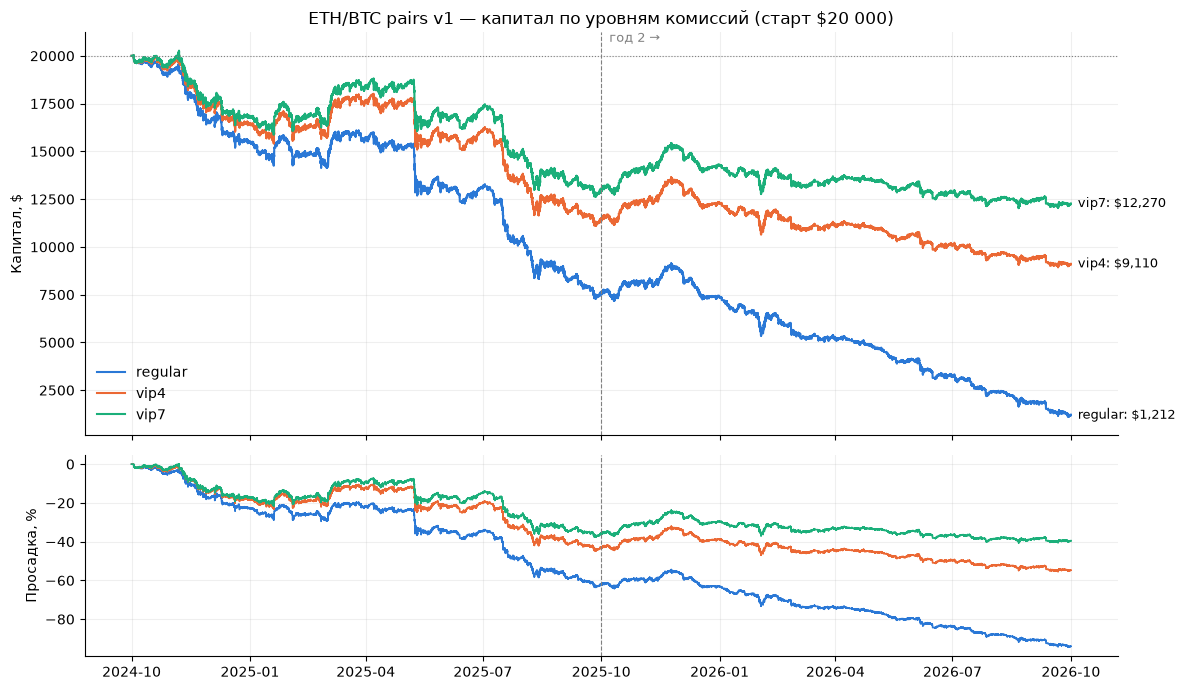

In [13]:
import matplotlib.pyplot as plt
from src.metrics import max_drawdown

time = pl.from_epoch(df["open_time"], time_unit="ms").to_numpy()
oos_time = time[split]
colors = {"regular": "#2a78d6", "vip4": "#eb6834", "vip7": "#1baf7a"}   # фиксированный порядок цветов

curves = {}
for tier in ("regular", "vip4", "vip7"):
    r = run_backtest(df["open_a"].to_numpy(), df["open_b"].to_numpy(),
                     df["close_a"].to_numpy(), df["close_b"].to_numpy(),
                     tradable, z, tier)
    curves[tier] = r["equity"]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})

for tier, eq in curves.items():
    ax1.plot(time, eq, color=colors[tier], linewidth=1.5, label=tier)
    ax1.annotate(f"{tier}: ${eq[-1]:,.0f}", xy=(time[-1], eq[-1]),        # подпись в конце линии
                 xytext=(5, 0), textcoords="offset points", va="center", fontsize=9)
    peak = np.maximum.accumulate(eq)
    ax2.plot(time, (eq / peak - 1) * 100, color=colors[tier], linewidth=1.2)

ax1.axhline(config.CAPITAL, color="grey", linewidth=0.8, linestyle=":")
for ax in (ax1, ax2):
    ax.axvline(oos_time, color="grey", linewidth=0.8, linestyle="--")
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

ax1.set_title("ETH/BTC pairs v1 — капитал по уровням комиссий (старт $20 000)")
ax1.set_ylabel("Капитал, $")
ax1.legend(loc="lower left", frameon=False)
ax1.text(oos_time, ax1.get_ylim()[1], "  год 2 →", va="top", fontsize=9, color="grey")
ax2.set_ylabel("Просадка, %")

plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "02_equity_drawdown.png", dpi=150, bbox_inches="tight")
plt.show()

### Проверим ступеньки: 5 худших сделок

In [14]:
worst = sorted(trades, key=lambda t: t["pnl"])[:5]
for t in worst:
    print(time[t["entry_t"]], "→", time[t["exit_t"]],
          "| направление:", t["direction"], "| причина:", t["reason"],
          "| PnL:", round(t["pnl"], 2),
          "| свечей:", t["exit_t"] - t["entry_t"])

2025-05-08T04:00:00.000000 → 2025-05-10T04:00:00.000000 | направление: -1 | причина: time | PnL: -1920.01 | свечей: 576
2025-07-15T05:40:00.000000 → 2025-07-17T05:40:00.000000 | направление: -1 | причина: time | PnL: -1231.39 | свечей: 576
2025-08-06T18:05:00.000000 → 2025-08-08T18:05:00.000000 | направление: -1 | причина: time | PnL: -864.35 | свечей: 576
2026-01-30T23:10:00.000000 → 2026-02-01T23:10:00.000000 | направление: 1 | причина: time | PnL: -785.21 | свечей: 576
2025-02-03T01:45:00.000000 → 2025-02-03T01:55:00.000000 | направление: 1 | причина: stop | PnL: -515.75 | свечей: 2
